# 01. Explore the Data

**INSY 674 group project: hotel booking cancellations**
*Section owner: data exploration. Checklist reference: "Explore the Data" (Géron, Appendix B).*

**How to read this notebook.** Every code cell is followed by a short **Takeaway** that says what the output means and what we should do about it. The takeaways are numbered **F1, F2, ...** (findings) so teammates can reference them in the Prepare, Model and Slides sections. The last section collects everything in one place.

**Targets.** The team's *Frame the Problem* section has three tasks: (1) forecast rooms free per hotel per night, (2) classify `is_canceled`, and (3) predict how many days before arrival a cancellation happens. This notebook explores `is_canceled` (task 2) in depth. The data-quality findings apply to all three tasks.

| Checklist item | Where in this notebook |
|---|---|
| Copy of the data for exploration | Section 1 |
| Name, type, % missing, noise, distribution, usefulness of each attribute | Section 2 (data dictionary) and 3 (data quality) |
| Identify the target | Section 4 |
| Visualise the data | Sections 5 and 6 |
| Correlations | Section 7 |
| Promising transformations, extra data | Section 9 |
| Document what you learned | Sections 8 and 10 |

## 1. Setup and a working copy of the data

In [33]:
%pip install seaborn
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Locate the untouched data file in either the team repository or alongside this notebook.
DATA_CANDIDATES = [Path("../data/raw/hotel_bookings.csv"), Path("hotel_bookings.csv"),
                   Path("hotel_bookings(1)(1).csv"), Path("/mnt/data/hotel_bookings(1)(1).csv")]
RAW = next((path for path in DATA_CANDIDATES if path.is_file()), None)
if RAW is None:
    raise FileNotFoundError("Place hotel_bookings.csv in ../data/raw/ or beside this notebook.")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

# Two colours that stay distinguishable for colour-blind readers.
BLUE, ORANGE, GREY = "#0072B2", "#D55E00", "#6b7280"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10})

def savefig(name):
    """Save into reports/figures (for the slides) and show it in the notebook."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

raw = pd.read_csv(RAW)      # note: pandas reads the text 'NULL' in this file as a missing value (NaN)
df = raw.copy()             # the working copy we explore. 'raw' stays as loaded.
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns, {raw.memory_usage(deep=True).sum()/1e6:.0f} MB in memory")
df.head(3)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


119,390 rows x 32 columns, 98 MB in memory


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


**Takeaway (F1).** The file has 119,390 rows and 32 columns and is small enough to explore in full, so **no sampling is needed**. The checklist asks for "a copy of the data for exploration": `df = raw.copy()` is that copy, and the original file in `data/raw/` is never modified.

In [34]:
# Exploration-only helper columns, built on the copy. These are NOT the final feature engineering;
# that belongs in the "Prepare the Data" section. We just need them to look at the data.
MONTH_NUM = {m: i + 1 for i, m in enumerate(["January","February","March","April","May","June","July",
             "August","September","October","November","December"])}
MONTH_ORDER = list(MONTH_NUM)

df["total_nights"]  = df.stays_in_weekend_nights + df.stays_in_week_nights
df["total_guests"]  = df.adults + df.children.fillna(0) + df.babies
df["arrival_date"]  = pd.to_datetime(dict(year=df.arrival_date_year,
                                          month=df.arrival_date_month.map(MONTH_NUM),
                                          day=df.arrival_date_day_of_month))
df["booking_date"]  = df.arrival_date - pd.to_timedelta(df.lead_time, unit="D")   # when the booking was made
df["room_mismatch"] = (df.reserved_room_type != df.assigned_room_type).astype(int)
df["lead_bin"] = pd.cut(df.lead_time, [-1, 7, 30, 90, 180, 365, 1000],
                        labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"])

ORIGINAL_COLS = list(raw.columns)
OVERALL = df.is_canceled.mean()
print(f"Overall cancellation rate: {OVERALL:.1%}")

Overall cancellation rate: 37.0%


## 2. Data dictionary: what each attribute is and whether it is useful

The checklist asks us to study **each attribute** for: name, type, % missing, noise, distribution and usefulness. Part A is computed from the data (so it cannot go stale). Part B is our written judgement, based on the plots and tables further down.

In [35]:
# Part A: computed profile of every original column
rows = []
for c in ORIGINAL_COLS:
    s = df[c]
    num = pd.api.types.is_numeric_dtype(s)
    rows.append({
        "attribute": c,
        "dtype": str(s.dtype),
        "n_unique": s.nunique(),
        "% missing": round(s.isna().mean() * 100, 2),
        "min": s.min() if num else "",
        "median": s.median() if num else "",
        "max": s.max() if num else "",
        "skew": round(s.skew(), 2) if num else "",
        "most common value": f"{s.mode().iloc[0]} ({(s == s.mode().iloc[0]).mean():.0%})",
    })
profile = pd.DataFrame(rows).set_index("attribute")
from pathlib import Path

# Create the output folder if it doesn't exist
output_dir = Path("../docs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the CSV file
profile.to_csv(output_dir / "attribute_profile_computed.csv")

print("Attribute profile saved successfully!")
profile

Attribute profile saved successfully!


,dtype,n_unique,% missing,min,median,max,skew,most common value
attribute,,,,,,,,
hotel,str,2,0.00,,,,,City Hotel (66%)
is_canceled,int64,2,0.00,0,0.0,1,0.54,0 (63%)
lead_time,int64,479,0.00,0,69.0,737,1.35,0 (5%)
arrival_date_year,int64,3,0.00,2015,2016.0,2017,-0.23,2016 (47%)
arrival_date_month,str,12,0.00,,,,,August (12%)
arrival_date_week_number,int64,53,0.00,1,28.0,53,-0.01,33 (3%)
arrival_date_day_of_month,int64,31,0.00,1,16.0,31,-0.0,17 (4%)
stays_in_weekend_nights,int64,17,0.00,0,1.0,19,1.38,0 (44%)
stays_in_week_nights,int64,35,0.00,0,2.0,50,2.86,2 (28%)


**Part B: our written profile of each attribute** (also saved as `docs/data_dictionary.md`).

| Attribute | Type | Noise / data quality | Distribution | Usefulness for predicting cancellation |
|---|---|---|---|---|
| `hotel` | Categorical (2) | None | City 66%, Resort 34% | **Useful.** City cancels 41.7%, Resort 27.8%. Consider interaction with other features or one model per hotel. |
| `is_canceled` | Binary 0/1 | None | 37.0% canceled | **TARGET.** Mildly imbalanced, not severe. |
| `lead_time` | Integer, 0 to 737 days | Long right tail; 481 bookings > 500 days (plausible but rare) | Right-skewed (skew 1.3), spike at 0-1 | **Very useful.** Strongest numeric signal (corr +0.29). Cancel rate climbs from 10% (0-7 days) to 68% (> 1 year). |
| `arrival_date_year` | Integer, 2015-2017 | None | 3 values; data runs Jul 2015 to Aug 2017 | **Limited as a feature** (only 3 values, cannot generalise to a new year). **Valuable as a time index** for a time-based train/test split. |
| `arrival_date_month` | Categorical (ordinal), 12 names | None | Peak Jul/Aug; low Dec-Jan | **Moderate.** Cancel rate ranges 30.5% (Jan) to 41.5% (Jun). Must be ordered or converted to a number. |
| `arrival_date_week_number` | Integer, 1-53 | None | Roughly seasonal | **Redundant** with month. Pick one. |
| `arrival_date_day_of_month` | Integer, 1-31 | None | About uniform | **Low.** Correlation with target is about 0. Day-of-week (derived from the full date) is more meaningful. |
| `stays_in_weekend_nights` | Integer, 0-19 | Outliers (up to 19) | Right-skewed, most are 0-2 | **Low alone**; combine with week nights into `total_nights`. |
| `stays_in_week_nights` | Integer, 0-50 | Outliers (up to 50) | Right-skewed, most are 1-3 | **Low alone**; combine into `total_nights`. Stays > 14 nights cancel 55% (439 rows). |
| `adults` | Integer, 0-55 | Impossible values: 0 adults and up to 55 adults | At least half are exactly 2 | **Moderate.** Needs cleaning (0 adults and >10 are likely errors or group blocks). |
| `children` | Float (should be integer), 0-10 | 4 missing values | 93% are 0 | **Low.** Impute 0 for the 4 missing. |
| `babies` | Integer, 0-10 | Outliers (10 babies) | > 99% are 0 | **Low.** Turn into `has_babies` flag or merge into `total_guests`. |
| `meal` | Categorical (5) | `Undefined` and `SC` both mean 'no meal package' (9.9% combined) | BB 77%, HB 12%, SC 9%, FB 0.7%, Undefined 1% | **Low-moderate.** Merge `Undefined` into `SC`. FB looks high (60%) but only 798 rows. |
| `country` | Categorical (ISO-3 code), 177 values | 488 missing (0.4%) | Very top-heavy: PRT 41%, then GBR, FRA, ESP, DEU | **Useful but high-cardinality.** PRT cancels 56.6%, GBR/FRA/DEU 17-20%. Group rare countries into 'Other'. |
| `market_segment` | Categorical (8) | 2 'Undefined' rows | Online TA 47%, Offline TA/TO 20%, Groups 17% | **Very useful.** Groups cancel 61%, Direct 15%, Corporate 19%. |
| `distribution_channel` | Categorical (5) | 5 'Undefined' rows | TA/TO 82% | **Moderate, overlaps** with market_segment. Check redundancy before keeping both. |
| `is_repeated_guest` | Binary 0/1 | None | 3.2% are 1 | **Weak-moderate** (corr -0.08). Repeat guests cancel less. |
| `previous_cancellations` | Integer, 0-26 | Heavy tail | 94.6% are 0 | **Useful but odd.** Exactly 1 previous cancellation = 94% cancel; 2+ drops back to about 30%. See anomaly section. |
| `previous_bookings_not_canceled` | Integer, 0-72 | Heavy tail | 97% are 0 | **Weak.** Mostly zero. Candidate for a `has_history` flag. |
| `reserved_room_type` | Categorical (10 letters, anonymised) | None | A = 72%, D = 16% | **Weak-moderate.** Letters are anonymised so no ordering is known. |
| `assigned_room_type` | Categorical (12 letters) | None | Same as reserved | **Timing risk.** Real assignment happens at/after check-in. Differs from reserved on 12.5% of rows, and those cancel only 5.4% (vs 41.6%). |
| `booking_changes` | Integer, 0-21 | Heavy tail | Zero for most bookings | **Useful but timing risk.** 0 changes = 41% cancel, 1+ changes = 14-20%. Changes accumulate after booking. |
| `deposit_type` | Categorical (3) | Suspicious pattern, see anomaly section | No Deposit 88%, Non Refund 12%, Refundable 0.1% | **Very useful but suspicious.** Non Refund bookings cancel 99.4%, the opposite of what you would expect. |
| `agent` | Float ID (should be categorical), 333 IDs | 13.7% missing (means 'no agent', not unknown) | Long tail of agent IDs | **Moderate.** Treat as categorical with an explicit 'no agent' level. Group small agents. |
| `company` | Float ID (should be categorical), 352 IDs | 94.3% missing (means 'no company') | Almost always missing | **Low as an ID.** Convert to a `has_company` flag (66% of those bookings are Corporate). |
| `days_in_waiting_list` | Integer, 0-391 | Heavy tail | 97% are 0 | **Low-moderate.** Waitlisted bookings cancel 64% vs 36%. Also only known after booking. |
| `customer_type` | Categorical (4) | None | Transient 75%, Transient-Party 21% | **Moderate.** Group customers cancel 10%, Transient 41%. |
| `adr` | Float (average daily rate) | 1 negative, 1,959 zeros (1.6%), one extreme value of 5,400 | Right-skewed, median 94.6 | **Weak linearly** (corr +0.05). Zeros are mostly complimentary/free stays. Clip or cap the 5,400 outlier. |
| `required_car_parking_spaces` | Integer, 0-8 | None | 94% are 0 | **Timing risk / leakage-like.** Every booking with parking is a non-cancel (0% cancel rate). |
| `total_of_special_requests` | Integer, 0-5 | None | 59% are 0 | **Useful but timing risk.** 0 requests = 48% cancel, 1+ requests = 5-22%. Requests may be added after booking. |
| `reservation_status` | Categorical (Check-Out, Canceled, No-Show) | None | 63% Check-Out, 36% Canceled, 1% No-Show | **LEAKAGE. Drop.** It is the outcome written as text. Canceled + No-Show = is_canceled exactly. |
| `reservation_status_date` | Date | None | Jul 2015 to Sep 2017 | **LEAKAGE. Drop.** Date the final status was set. For 95% of canceled bookings it is the cancel date. |

**Takeaway (F2).** Only **four columns have missing values**: `company` (94.3%), `agent` (13.7%), `country` (0.4%) and `children` (4 rows). For `company` and `agent` the missing value is **not an error**: it means "no company / no agent", so it carries information and should be kept as its own category rather than imputed. Two columns (`reservation_status`, `reservation_status_date`) are **leakage** and must never be used as features (see Section 5).

## 3. Data quality: duplicates, impossible values, outliers

In [36]:
# 3a. Exact duplicate rows (all 32 columns identical)
n_dup = df[ORIGINAL_COLS].duplicated().sum()
dup_flag = df[ORIGINAL_COLS].duplicated(keep="first")
print(f"Duplicate rows: {n_dup:,} ({n_dup/len(df):.1%} of the data)")
print(f"Cancel rate among the duplicate rows : {df[dup_flag].is_canceled.mean():.1%}")
print(f"Cancel rate among all other rows     : {df[~dup_flag].is_canceled.mean():.1%}")
print(f"Share of duplicate rows that are 'Non Refund' deposits: {(df[dup_flag].deposit_type == 'Non Refund').mean():.1%}")

Duplicate rows: 31,994 (26.8% of the data)
Cancel rate among the duplicate rows : 63.1%
Cancel rate among all other rows     : 27.5%
Share of duplicate rows that are 'Non Refund' deposits: 42.3%


In [37]:
# 3b. Impossible or suspicious values
checks = {
    "0 guests in total (adults+children+babies = 0)": (df.total_guests == 0),
    "0 nights stayed": (df.total_nights == 0),
    "ADR < 0": (df.adr < 0),
    "ADR = 0": (df.adr == 0),
    "ADR > 1,000": (df.adr > 1000),
    "More than 10 adults": (df.adults > 10),
    "Stay longer than 14 nights": (df.total_nights > 14),
    "Lead time > 500 days": (df.lead_time > 500),
}
rows = [{"check": k, "rows": int(v.sum()), "% of data": round(v.mean()*100, 2),
         "cancel rate": round(df[v].is_canceled.mean()*100, 1) if v.sum() else np.nan} for k, v in checks.items()]
pd.DataFrame(rows).set_index("check")

,rows,% of data,cancel rate
check,,,
0 guests in total (adults+children+babies = 0),180,0.15,13.9
0 nights stayed,715,0.60,4.9
ADR < 0,1,0.00,0.0
ADR = 0,1959,1.64,10.9
"ADR > 1,000",1,0.00,100.0
More than 10 adults,12,0.01,100.0
Stay longer than 14 nights,439,0.37,55.4
Lead time > 500 days,481,0.40,85.7


**Takeaway (F3): duplicates are the biggest data quality issue.** **31,994 rows (26.8%) are exact copies** of an earlier row. There is **no booking ID**, so we cannot tell whether they are real separate bookings (e.g. five identical rooms booked by one group) or database repeats. Two reasons they matter:

1. **Leakage into the test set.** If the same row lands in both train and test after a random split, the model is graded on rows it has already memorised. This inflates the test score, which the rubric explicitly penalises ("data leakage").
2. **They distort the target rate.** The cancel rate is 37.0% with duplicates but **27.5% without**, because duplicates cancel at 63%. They are also where most of the odd `Non Refund` behaviour comes from (F11).

**Recommendation:** drop exact duplicates *before* splitting into train and test, and report results on the de-duplicated data. We should also run one experiment with them kept, so we can say what difference it makes.

**Caveat from the forecasting task:** the team also forecasts rooms free per night by counting bookings. If these rows are genuinely separate bookings (for example several identical rooms booked together), dropping them would undercount demand. With no booking ID we cannot tell, so the forecast should be run both ways.

**Takeaway (F4): small clean-up items.** 180 bookings have zero guests, 715 have zero nights, 1,959 have an ADR of 0 (mostly complimentary stays, the cancel rate is only 11%), 1 has a negative ADR, and 1 has an ADR of 5,400 (the next highest is 510). These are all tiny (<2%) so the simplest approach is to drop zero-guest rows and cap ADR; none of them is worth heavy effort.

## 4. The target: `is_canceled`

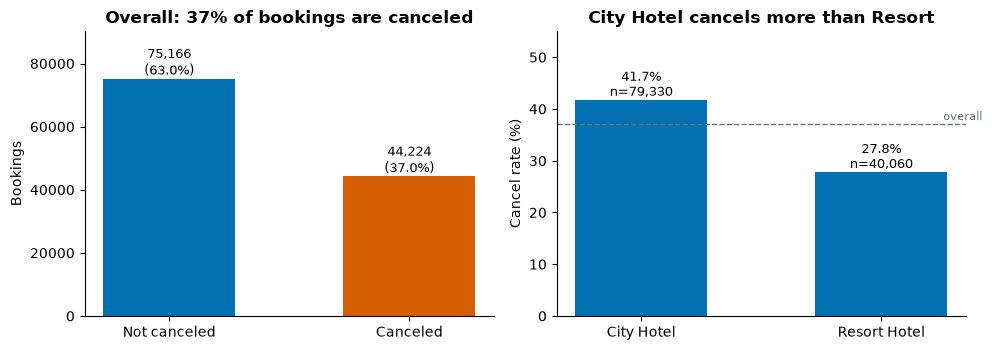

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

counts = df.is_canceled.value_counts().sort_index()
axes[0].bar(["Not canceled", "Canceled"], counts.values, color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.2)
axes[0].set_title("Overall: 37% of bookings are canceled")
axes[0].set_ylabel("Bookings")

by_hotel = df.groupby("hotel").is_canceled.agg(["mean", "size"])
axes[1].bar(by_hotel.index, by_hotel["mean"] * 100, color=BLUE, width=0.55)
for i, (m, n) in enumerate(zip(by_hotel["mean"], by_hotel["size"])):
    axes[1].text(i, m * 100, f"{m:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=9)
axes[1].axhline(OVERALL * 100, color=GREY, ls="--", lw=1); axes[1].text(1.42, OVERALL*100+0.8, "overall", color=GREY, fontsize=8, ha="right")
axes[1].set_ylim(0, 55); axes[1].set_ylabel("Cancel rate (%)")
axes[1].set_title("City Hotel cancels more than Resort")
savefig("01_target_balance")

**Takeaway (F5).** The target is **binary and mildly imbalanced: 37.0% canceled**. That is not extreme, so plain accuracy is not useless, but a model that predicts "never cancels" would already score 63%. Any model must beat that baseline, and we should report **precision, recall and F1 / PR-AUC** (not only accuracy). The two hotels differ a lot (**City 41.7% vs Resort 27.8%**), so `hotel` is an important feature.

## 5. Leakage check: which columns are not allowed to be features?

**Why this matters.** A model is only useful if it predicts using information that is available *at the moment we want the prediction*. If a column is only filled in *after* the booking is canceled or completed, the model is "cheating". Although it looks brilliant in testing, it is useless in real life because of the data leakage.

In [39]:
print("reservation_status vs is_canceled (row counts):")
display(pd.crosstab(df.reservation_status, df.is_canceled))

# When was the final status recorded relative to the arrival date?
status_date = pd.to_datetime(df.reservation_status_date)
canceled = df.is_canceled == 1
print(f"\nCanceled bookings whose status date is BEFORE arrival : {(status_date[canceled] < df.arrival_date[canceled]).mean():.1%}")
print(f"Checked-out bookings whose status date is ON/AFTER arrival: {(status_date[~canceled] >= df.arrival_date[~canceled]).mean():.1%}")

reservation_status vs is_canceled (row counts):


is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207



Canceled bookings whose status date is BEFORE arrival : 95.3%
Checked-out bookings whose status date is ON/AFTER arrival: 100.0%


**Takeaway (F6).** `reservation_status` **is the target written in words** (Canceled and No-Show are always `is_canceled = 1`, Check-Out is always 0). `reservation_status_date` is the date that outcome was recorded (for canceled bookings it is the cancellation date, before arrival 95% of the time). **Both must be dropped as features.** (`reservation_status_date` is still useful for building the Task 3 target, the days between cancellation and arrival, but never as an input.) Including them would give a near-perfect score that means nothing. 

**Softer, timing-related risks.** Some other columns are not the outcome itself, but they get filled in *after* the booking is made, so their values depend on *when* we make the prediction:

| Column | When is it known? | Evidence in data | Risk |
|---|---|---|---|
| `required_car_parking_spaces` | At check-in | **0% of bookings with parking were canceled** (7,416 rows) | High: acts like a "did they show up" flag |
| `assigned_room_type` | At/after check-in | Mismatch with reserved room: 5.4% cancel vs 41.6% | High |
| `booking_changes` | Accumulates between booking and arrival | 0 changes: 41% cancel; 1+: 14-20% | Medium |
| `total_of_special_requests` | Can be added after booking | 0 requests: 48% cancel; 1+: 5-22% | Medium |
| `days_in_waiting_list` | After booking is processed | Waitlisted: 64% cancel vs 36% | Low-medium |
| All other columns | At booking time | | Low |

**Update after the team's *Frame the Problem* section:** the team will forecast at several lead times (30, 14, 7 and 1 days out). The file only stores each booking's *final* values, so we cannot know what `booking_changes` or `total_of_special_requests` looked like 30 days before arrival. Parking and assigned room should be excluded at every horizon. Booking changes and special requests should be excluded, or at least tested with and without, so that no forecast quietly uses information from the future.


## 6. Distributions: what does each attribute look like?

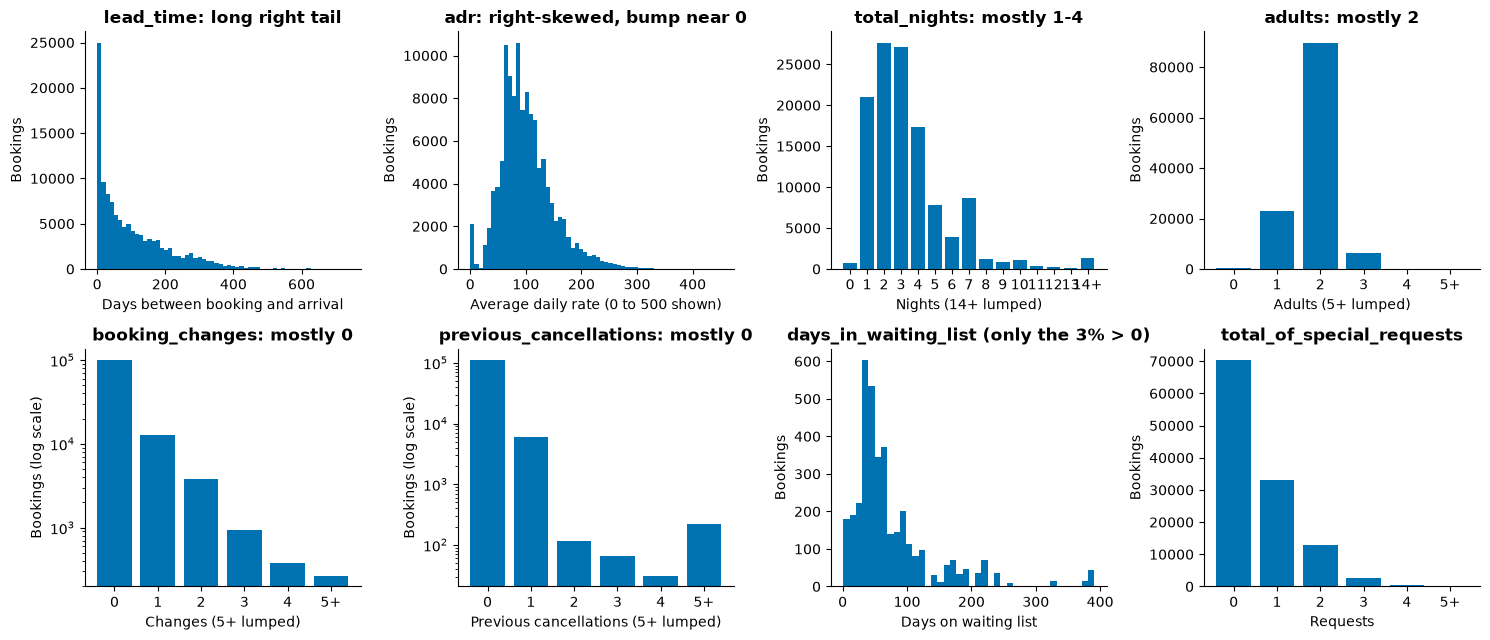

In [40]:
def discrete_bar(ax, s, cap, title, logy=False, xlabel=""):
    """Bar chart of an integer column, lumping everything >= cap into one 'cap+' bar."""
    s = s.clip(upper=cap)
    vc = s.value_counts().sort_index()
    labels = [str(int(i)) if i < cap else f"{int(cap)}+" for i in vc.index]
    ax.bar(labels, vc.values, color=BLUE)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Bookings")
    if logy: ax.set_yscale("log"); ax.set_ylabel("Bookings (log scale)")

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
a = axes.ravel()
a[0].hist(df.lead_time, bins=60, color=BLUE); a[0].set_title("lead_time: long right tail"); a[0].set_xlabel("Days between booking and arrival"); a[0].set_ylabel("Bookings")
a[1].hist(df.adr[(df.adr >= 0) & (df.adr <= 500)], bins=60, color=BLUE); a[1].set_title("adr: right-skewed, bump near 0"); a[1].set_xlabel("Average daily rate (0 to 500 shown)"); a[1].set_ylabel("Bookings")
discrete_bar(a[2], df.total_nights, 14, "total_nights: mostly 1-4", xlabel="Nights (14+ lumped)")
discrete_bar(a[3], df.adults, 5, "adults: mostly 2", xlabel="Adults (5+ lumped)")
discrete_bar(a[4], df.booking_changes, 5, "booking_changes: mostly 0", logy=True, xlabel="Changes (5+ lumped)")
discrete_bar(a[5], df.previous_cancellations, 5, "previous_cancellations: mostly 0", logy=True, xlabel="Previous cancellations (5+ lumped)")
a[6].hist(df.days_in_waiting_list[df.days_in_waiting_list > 0], bins=40, color=BLUE); a[6].set_title("days_in_waiting_list (only the 3% > 0)"); a[6].set_xlabel("Days on waiting list"); a[6].set_ylabel("Bookings")
discrete_bar(a[7], df.total_of_special_requests, 5, "total_of_special_requests", xlabel="Requests")
savefig("02_numeric_distributions")

**Takeaway (F7).** Nearly every numeric column is **heavily right-skewed or "mostly zero"**:

- `lead_time`, `adr` and `total_nights` have long right tails. A **log or square-root transform** (or bucketing) will help linear / distance-based models; tree models do not care.
- `booking_changes`, `previous_cancellations`, `previous_bookings_not_canceled`, `days_in_waiting_list`, `babies` and `children` are 90-99% zeros. For these, a **yes/no flag** (`has_changes`, `has_history`, `was_waitlisted`) often carries all of the signal.
- Nothing is close to a bell curve, so we should avoid models that assume normally distributed inputs without transforming first.

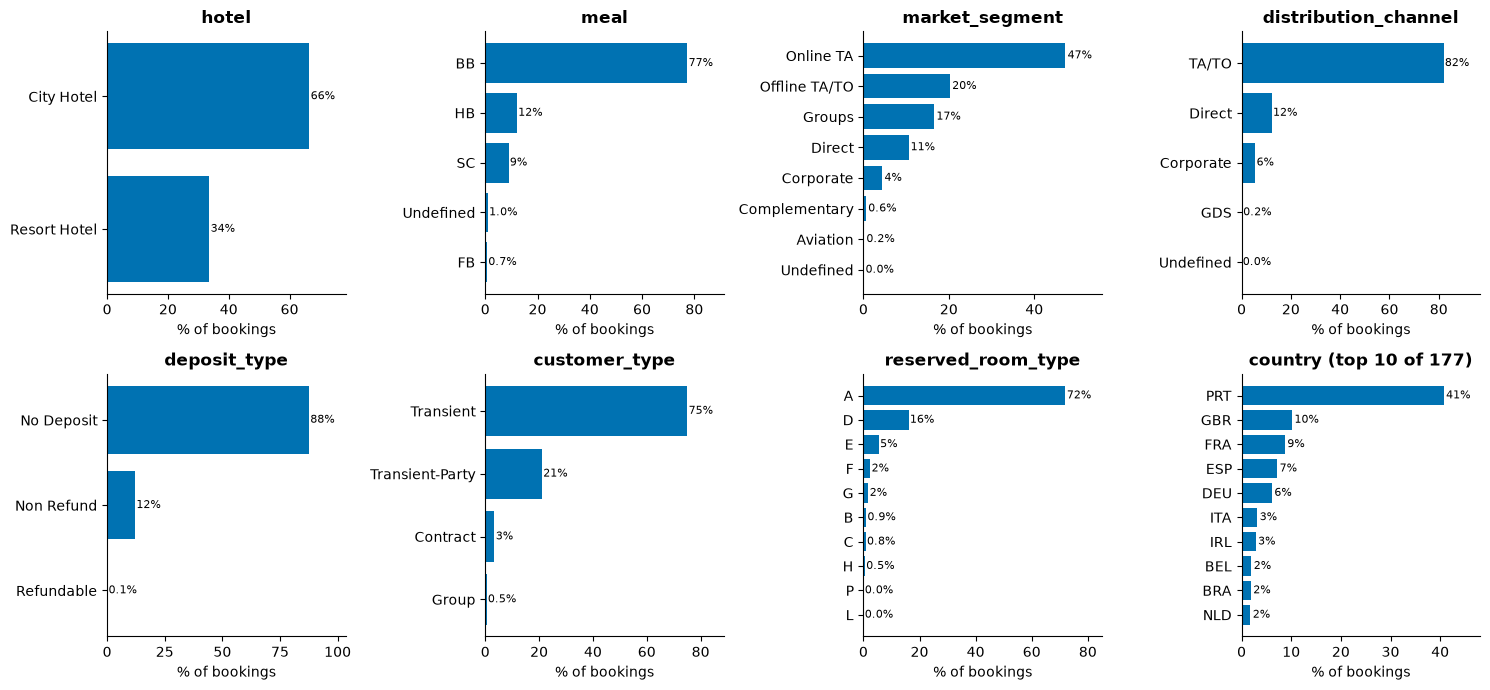

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
a = axes.ravel()
top_countries = df.country.value_counts().head(10)
panels = [("hotel", df.hotel.value_counts()), ("meal", df.meal.value_counts()),
          ("market_segment", df.market_segment.value_counts()), ("distribution_channel", df.distribution_channel.value_counts()),
          ("deposit_type", df.deposit_type.value_counts()), ("customer_type", df.customer_type.value_counts()),
          ("reserved_room_type", df.reserved_room_type.value_counts()), ("country (top 10 of 177)", top_countries)]
for ax, (name, vc) in zip(a, panels):
    pct = vc / len(df) * 100
    ax.barh(pct.index[::-1], pct.values[::-1], color=BLUE)
    for y, v in enumerate(pct.values[::-1]):
        ax.text(v + 0.5, y, f"{v:.0f}%" if v >= 1 else f"{v:.1f}%", va="center", fontsize=8)
    ax.set_title(name); ax.set_xlabel("% of bookings"); ax.set_xlim(0, pct.max() * 1.18)
savefig("03_categorical_distributions")

**Takeaway (F8).** The categorical columns are **dominated by one or two levels** (Online TA = 47% of bookings, TA/TO = 82% of channels, Transient = 75% of customers, room type A = 72%, Portugal = 41% of guests). Two practical consequences: (1) rare levels (e.g. `Refundable` deposit = 162 rows, `Undefined` segments = 2 rows) are too small to learn from and should be merged or ignored; (2) `country` has 177 values, so one-hot encoding would add 177 columns. **Group countries outside the top ~10 into "Other"**, or use target / frequency encoding inside the cross-validation pipeline.

## 7. What drives cancellation? Cancel rate by attribute

For each chart below, the bar height is the **cancel rate for that group** and the dashed line is the overall rate (37.0%). The small `n=` labels show how many bookings are in each group, because a high rate on a tiny group is not reliable.

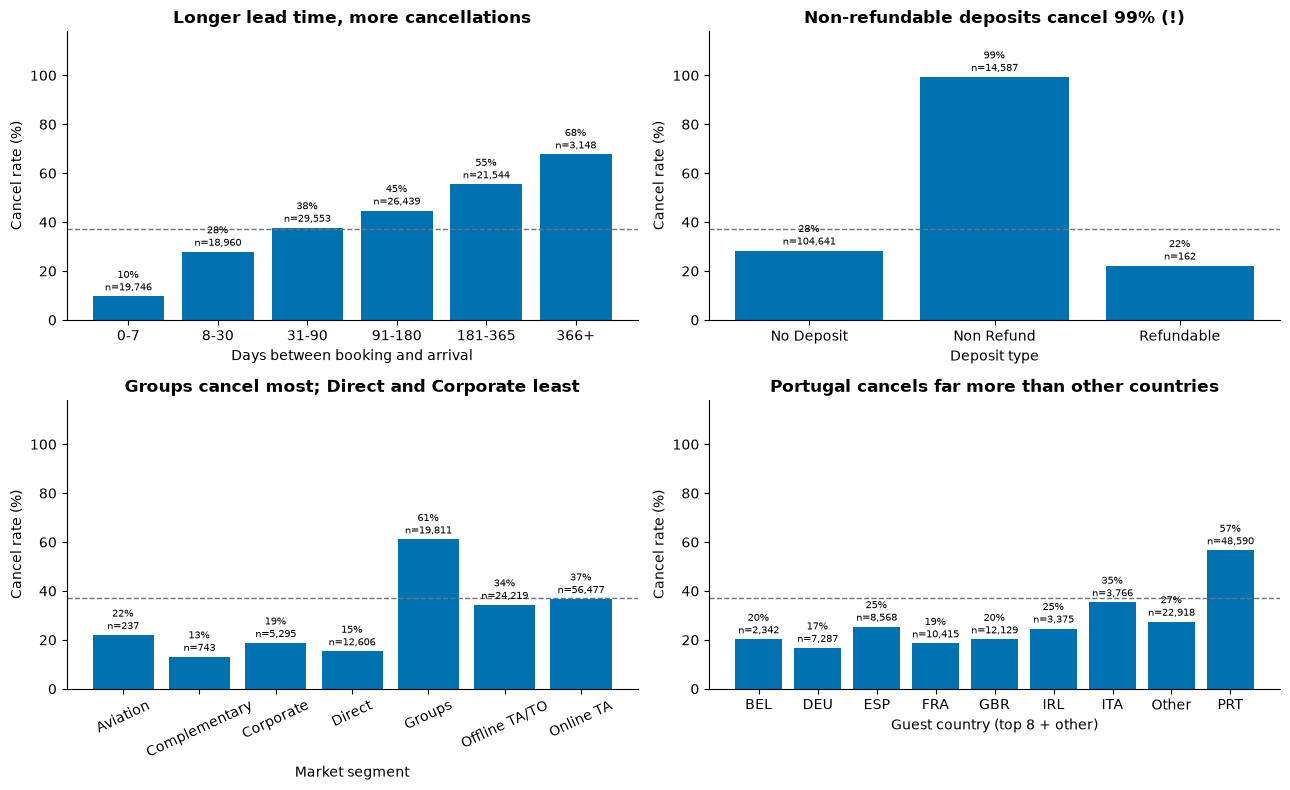

In [42]:
def cancel_rate(ax, col, title, xlabel="", order=None, min_n=0, rotate=0, data=None):
    d = df if data is None else data
    g = d.groupby(col, observed=True).is_canceled.agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    if order is not None: g = g.reindex([o for o in order if o in g.index])
    ax.bar(g.index.astype(str), g["mean"] * 100, color=BLUE)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m * 100 + 1, f"{m*100:.0f}%\nn={n:,}", ha="center", va="bottom", fontsize=7.5)
    ax.axhline(d.is_canceled.mean() * 100, color=GREY, ls="--", lw=1)
    ax.set_ylim(0, 118); ax.set_ylabel("Cancel rate (%)"); ax.set_xlabel(xlabel); ax.set_title(title)
    ax.tick_params(axis="x", rotation=rotate)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
cancel_rate(axes[0,0], "lead_bin", "Longer lead time, more cancellations", "Days between booking and arrival")
cancel_rate(axes[0,1], "deposit_type", "Non-refundable deposits cancel 99% (!)", "Deposit type")
cancel_rate(axes[1,0], "market_segment", "Groups cancel most; Direct and Corporate least", "Market segment", rotate=25, min_n=10)
cancel_rate(axes[1,1], df.country.where(df.country.isin(df.country.value_counts().head(8).index), "Other"),
            "Portugal cancels far more than other countries", "Guest country (top 8 + other)", rotate=0)
savefig("04_cancel_rate_main_drivers")

**Takeaway (F9): the strongest and most reliable drivers.**

- **Lead time:** cancel rate rises steadily from **10% (booked within a week)** to **68% (booked more than a year ahead)**. Intuitively, the further ahead you book, the more time life has to change your plans. This is a clean, explainable relationship and a good lead point for the slides.
- **Market segment:** **Groups cancel 61%**, Online TA 37%, Offline TA/TO 34%, versus **Direct 15% and Corporate 19%**.
- **Country:** **Portugal cancels 57%**, while the UK, France, Germany and Belgium are all 17-20%. (Both hotels are in Portugal, so these are mostly domestic bookings.)
- **Deposit type:** see the anomaly in F11 before trusting this one.

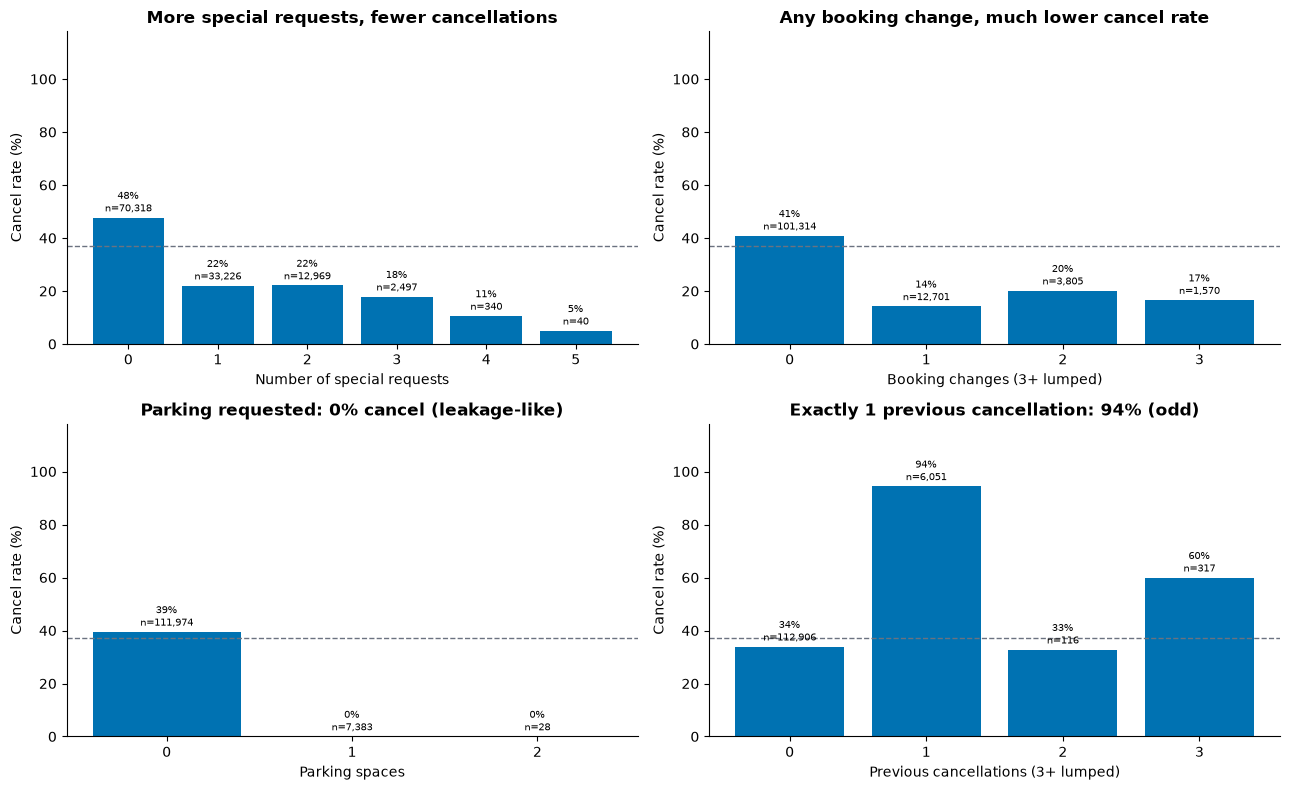

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
cancel_rate(axes[0,0], "total_of_special_requests", "More special requests, fewer cancellations", "Number of special requests")
cancel_rate(axes[0,1], df.booking_changes.clip(upper=3).rename("changes"), "Any booking change, much lower cancel rate", "Booking changes (3+ lumped)")
cancel_rate(axes[1,0], "required_car_parking_spaces", "Parking requested: 0% cancel (leakage-like)", "Parking spaces", min_n=10)
cancel_rate(axes[1,1], df.previous_cancellations.clip(upper=3).rename("prev"), "Exactly 1 previous cancellation: 94% (odd)", "Previous cancellations (3+ lumped)")
savefig("05_cancel_rate_behaviour")

**Takeaway (F10).** Booking *behaviour* columns are strong too: **no special requests = 48% cancel vs about 22% with one or more**, **no booking changes = 41% vs 14-20% with changes**, and **no parking = 39% vs 0% with parking**. As explained in F6, these are recorded after booking, so they carry a timing risk and the team must decide whether they are allowed. The `previous_cancellations` pattern is not what we expected (more previous cancellations should mean *more* risk, but 2+ drops to about 30%), which leads into the next finding.

In [44]:
# --- Investigating the two odd patterns: Non Refund deposits and previous_cancellations == 1
nr = df[df.deposit_type == "Non Refund"]
print("NON REFUND DEPOSIT bookings:", f"{len(nr):,}", f"({len(nr)/len(df):.1%} of data), cancel rate {nr.is_canceled.mean():.1%}")
print(f"  from Portugal: {(nr.country == 'PRT').mean():.1%}   City Hotel: {(nr.hotel == 'City Hotel').mean():.1%}")
display(nr.groupby("market_segment").is_canceled.agg(cancel_rate="mean", n="size").round(3))
print(f"  of these, rows that are exact duplicates: {df.loc[nr.index].duplicated(subset=ORIGINAL_COLS, keep=False).mean():.1%} (incl. originals)")

dd = df.drop_duplicates(subset=ORIGINAL_COLS)
print("\nAFTER DROPPING EXACT DUPLICATES:")
display(dd.groupby("deposit_type").is_canceled.agg(cancel_rate="mean", n="size").round(3))

p1 = df[df.previous_cancellations == 1]
print(f"\nprevious_cancellations == 1: {len(p1):,} rows, cancel rate {p1.is_canceled.mean():.1%}")
print(f"  from Portugal {(p1.country=='PRT').mean():.0%}; also Non Refund {(p1.deposit_type=='Non Refund').mean():.0%}; Groups segment {(p1.market_segment=='Groups').mean():.0%}")

NON REFUND DEPOSIT bookings: 14,587 (12.2% of data), cancel rate 99.4%
  from Portugal: 97.2%   City Hotel: 88.2%


,cancel_rate,n
market_segment,,
Corporate,0.934,334
Direct,0.842,19
Groups,0.993,9172
Offline TA/TO,0.999,5006
Online TA,0.946,56


  of these, rows that are exact duplicates: 98.1% (incl. originals)

AFTER DROPPING EXACT DUPLICATES:


,cancel_rate,n
deposit_type,,
No Deposit,0.267,86251
Non Refund,0.947,1038
Refundable,0.243,107



previous_cancellations == 1: 6,051 rows, cancel rate 94.4%
  from Portugal 96%; also Non Refund 58%; Groups segment 54%


**Takeaway (F11): two anomalies that do not look like real behaviour.**

1. **Non-refundable deposits cancel 99.4% of the time.** Common sense says people with a non-refundable deposit should cancel *least* (they lose money). Instead, 14,587 bookings (12% of data) are almost all cancellations. They are **97% from Portugal and almost all in the Groups or Offline TA/TO segments**, and the pattern is identical in 2015, 2016 and 2017. A likely explanation is that these hotels recorded some group or agency block reservations as "non-refund" and then canceled them in bulk, i.e. a **data-entry / business-process artifact rather than guest behaviour**. This is a hypothesis; we have no way to verify it from the file.
2. **Exactly one previous cancellation means 94% cancel**, but 2+ is only about 30%. 96% of those rows are from Portugal and 58% are also Non Refund, so this is the **same population** as above.

**Why it matters.** (a) A model will simply learn "Non Refund => canceled" and report a great score; that is real in this dataset but it will **not generalise to another hotel** and makes for a weak business story. (b) **After removing duplicates, the Non Refund group shrinks from 14,587 to 1,038 rows** (it is 42% of the duplicate rows, and 98% of Non Refund rows belong to a group of identical rows), though the remaining 1,038 still cancel 94.7%. So **de-duplication (F3) removes most, but not all, of the problem.**

**Recommendation:** report model performance both with and without `deposit_type`, and say clearly in the limitations that this field behaves oddly in this dataset.

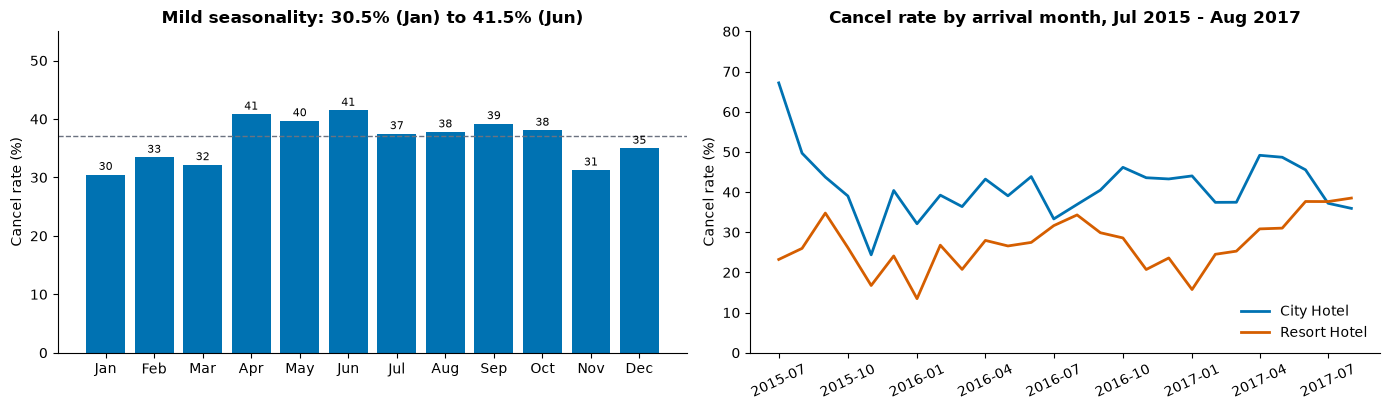

Arrival dates run from 2015-07-01 to 2017-08-31
Yearly cancel rate: {2015: 37.0, 2016: 35.9, 2017: 38.7}


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# Cancel rate by calendar month (Jul/Aug appear in 3 years, other months in 2)
mon = df.groupby("arrival_date_month").is_canceled.mean().reindex(MONTH_ORDER) * 100
axes[0].bar([m[:3] for m in MONTH_ORDER], mon.values, color=BLUE)
axes[0].axhline(OVERALL * 100, color=GREY, ls="--", lw=1)
axes[0].set_ylim(0, 55); axes[0].set_ylabel("Cancel rate (%)"); axes[0].set_title("Mild seasonality: 30.5% (Jan) to 41.5% (Jun)")
for i, v in enumerate(mon.values): axes[0].text(i, v + 0.8, f"{v:.0f}", ha="center", fontsize=8)

# Cancel rate over time, by hotel
ym = df.groupby([df.arrival_date.dt.to_period("M").dt.to_timestamp(), "hotel"]).is_canceled.mean().unstack() * 100
axes[1].plot(ym.index, ym["City Hotel"], color=BLUE, lw=2, label="City Hotel")
axes[1].plot(ym.index, ym["Resort Hotel"], color=ORANGE, lw=2, label="Resort Hotel")
axes[1].set_ylim(0, 80); axes[1].set_ylabel("Cancel rate (%)"); axes[1].set_title("Cancel rate by arrival month, Jul 2015 - Aug 2017")
axes[1].legend(frameon=False, loc="lower right"); axes[1].tick_params(axis="x", rotation=25)
savefig("06_time_patterns")
print("Arrival dates run from", df.arrival_date.min().date(), "to", df.arrival_date.max().date())
print("Yearly cancel rate:", (df.groupby("arrival_date_year").is_canceled.mean() * 100).round(1).to_dict())

**Takeaway (F12).** Seasonality exists but is **mild** (30.5% in January to 41.5% in June), and the yearly rate is stable (37.0%, 35.9%, 38.7%). The City Hotel is consistently above the Resort. Since the data covers **26 months (Jul 2015 to Aug 2017)**, we have a real choice: a **random split** (simple, but optimistic) or a **time-based split** (train on earlier months, test on the latest ones, which is closer to how a hotel would really use the model). We recommend a time-based hold-out for the final test set if the team has time, and say why in the slides.

## 8. Correlations

**Plain-English guide.** A correlation of +1 means "when A goes up, B always goes up", -1 means the opposite, 0 means no *straight-line* relationship. Correlation only captures straight-line patterns for numbers; it cannot see that a *category* (like deposit type) matters. So we use two tools: **Pearson correlation** for numbers, and **Cramér's V** (0 = unrelated, 1 = fully determines) for categories.

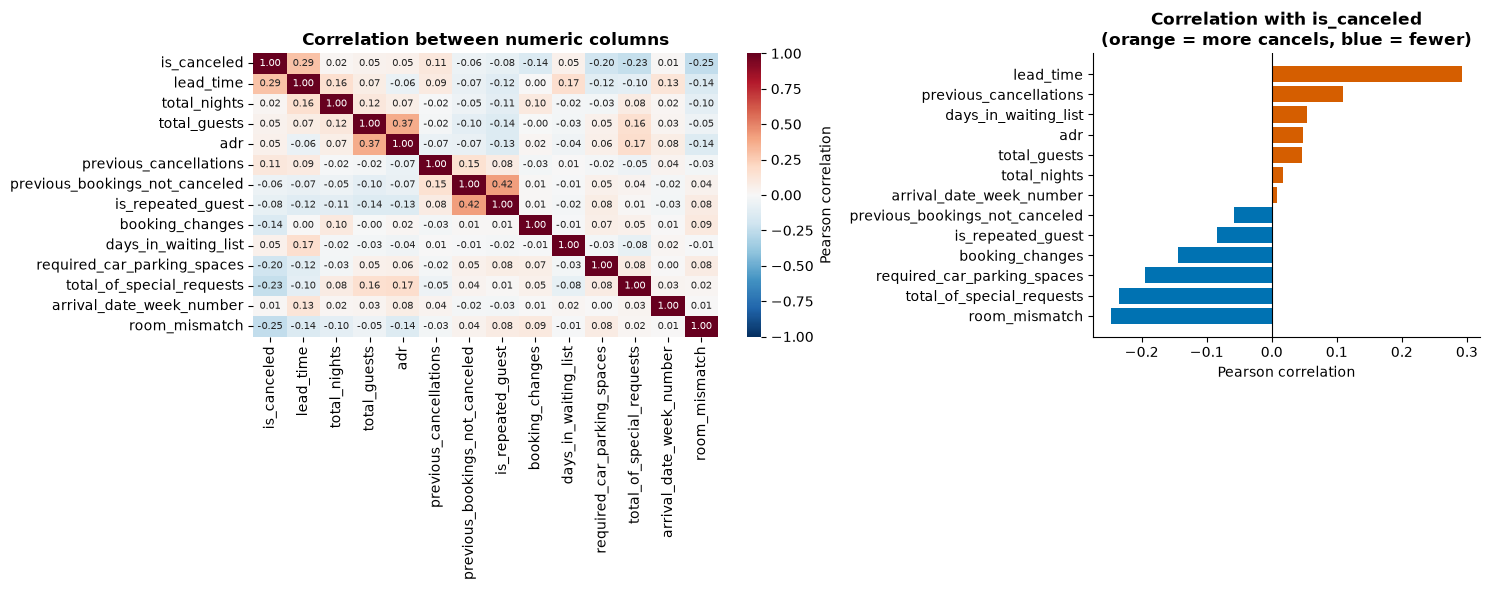

In [46]:
num_cols = ["is_canceled", "lead_time", "total_nights", "total_guests", "adr", "previous_cancellations",
            "previous_bookings_not_canceled", "is_repeated_guest", "booking_changes", "days_in_waiting_list",
            "required_car_parking_spaces", "total_of_special_requests", "arrival_date_week_number", "room_mismatch"]
corr = df[num_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0],
            cbar_kws={"label": "Pearson correlation"}, annot_kws={"fontsize": 7})
axes[0].set_title("Correlation between numeric columns")

t = corr["is_canceled"].drop("is_canceled").sort_values()
axes[1].barh(t.index, t.values, color=[ORANGE if v > 0 else BLUE for v in t.values])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Correlation with is_canceled\n(orange = more cancels, blue = fewer)")
axes[1].set_xlabel("Pearson correlation")
savefig("07_numeric_correlations")

**Takeaway (F13).** Against the target, the strongest straight-line relationships are **lead_time (+0.29)**, **special requests (-0.23)**, **parking (-0.20)**, **booking changes (-0.14)** and **previous cancellations (+0.11)**. The strongest of all is `room_mismatch` (-0.25), the timing-risk column from F6 (reserved and assigned room differ), so it should not be trusted. All are modest; no single number explains cancellation, which is a good sign that a multi-feature model will add value over a one-rule baseline. Between the features themselves, overlap is limited: the only pairs above 0.3 are `previous_bookings_not_canceled` with `is_repeated_guest` (0.42, both describe repeat guests) and `total_guests` with `adr` (0.37, more guests means a higher nightly price). `arrival_date_week_number` and the month encode the same information, as noted in the data dictionary.

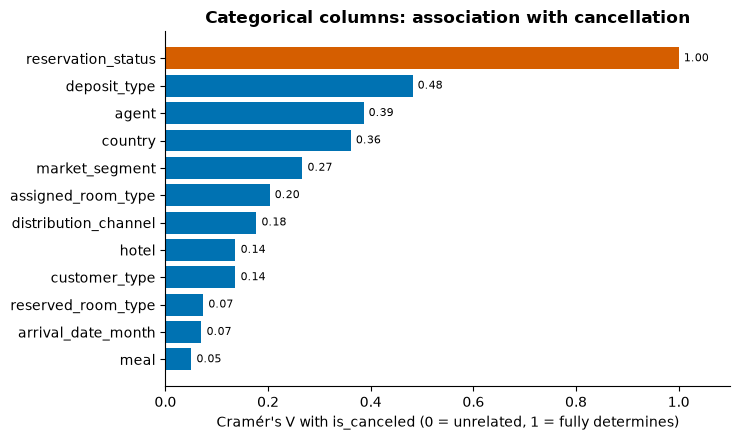

Cramér's V between pairs of categorical features (high = redundant):
        market_segment vs distribution_channel  : 0.69
    reserved_room_type vs assigned_room_type    : 0.78
        market_segment vs customer_type         : 0.28


In [47]:
def cramers_v(a, b):
    """Strength of association between two categorical variables, 0 (none) to 1 (perfect)."""
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

cats = ["deposit_type", "country", "market_segment", "agent", "reserved_room_type", "assigned_room_type",
        "customer_type", "distribution_channel", "hotel", "arrival_date_month", "meal", "reservation_status"]
cv = pd.Series({c: cramers_v(df[c].fillna("MISSING").astype(str), df.is_canceled) for c in cats}).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(cv.index, cv.values, color=[ORANGE if c == "reservation_status" else BLUE for c in cv.index])
for y, v in enumerate(cv.values): ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlim(0, 1.1); ax.set_xlabel("Cramér's V with is_canceled (0 = unrelated, 1 = fully determines)")
ax.set_title("Categorical columns: association with cancellation")
savefig("08_categorical_association")

# Redundancy between pairs of categorical columns
print("Cramér's V between pairs of categorical features (high = redundant):")
for a, b in [("market_segment", "distribution_channel"), ("reserved_room_type", "assigned_room_type"), ("market_segment", "customer_type")]:
    print(f"  {a:>20} vs {b:<22}: {cramers_v(df[a], df[b]):.2f}")

**Takeaway (F14).** Among categories, **`reservation_status` (1.00)** is the leakage column (it fully determines the target) and should be ignored. Of the legitimate features, **`deposit_type` (0.48), `agent` (0.39), `country` (0.36) and `market_segment` (0.27)** are the most associated with cancellation. `deposit_type` is high largely because of the anomaly in F11. The pair checks show `market_segment` and `distribution_channel` overlap heavily, and `reserved_room_type` and `assigned_room_type` overlap, so we do not need both of each pair.

## 9. Promising transformations and extra data

### Transformations to try in *Prepare the Data*

| Idea | Why | Applies to |
|---|---|---|
| Drop exact duplicates **before** the train/test split | Prevents identical rows appearing in both sets (F3); check the effect on per-night room counts | whole table |
| Drop `reservation_status`, `reservation_status_date` | Leakage (F6) | 2 columns |
| Decide whether to drop the "late-known" group | Timing leakage (F6) | `required_car_parking_spaces`, `assigned_room_type`, `booking_changes`, `total_of_special_requests`, `days_in_waiting_list` |
| Convert missing `agent` / `company` into a 'None' category, `company` into `has_company` | Missing means 'none', which is informative (F2) | `agent`, `company` |
| Group rare countries / agents into 'Other' | Avoids 177+ one-hot columns (F8) | `country`, `agent` |
| Merge `Undefined` meal into `SC` | Same meaning | `meal` |
| `total_nights`, `total_guests`, `is_family`, `has_babies` | Combine weak columns into one stronger one | stay and guest columns |
| Flags: `has_changes`, `was_waitlisted`, `has_history` | 90-99% zeros, the yes/no carries the signal (F7) | several count columns |
| Log or sqrt transform; cap at 99th percentile | Right skew and outliers (F7, F4) | `lead_time`, `adr`, `total_nights` |
| Lead-time buckets | Cancel rate is non-linear in lead time (F9) | `lead_time` |
| Date features: day of week, month number (cyclical), `is_weekend_arrival` | Stronger than day-of-month | arrival date |
| Ordered month or cyclic (sin/cos) encoding | Months are circular (Dec is next to Jan) | `arrival_date_month` |
| Impute, scale and encode **inside a scikit-learn Pipeline**, fit on train only | Avoids leakage, required by the rubric | all |

### Extra data that would be useful
- **A booking ID / guest ID:** would let us separate true duplicates from separate bookings and see a guest's history (F3).
- **Cancellation policy per booking** (free until X days before arrival): the real driver behind the deposit pattern (F11).
- **The cancellation timestamp**, not just the final status date, to model *when* cancellations happen, not just whether.
- **Price relative to the market** (competitor rates, discounts, whether the room was a promotion), because ADR alone is weakly predictive.
- **Local events / holiday calendar and weather:** these drive both demand and cancellation.
- **Hotel capacity and daily occupancy:** needed to turn a prediction into dollars (how many rooms could be resold, overbooking risk).
- **Cost inputs for the value case:** cost of an empty room night and cost of relocating a guest if we overbook and everyone shows up. These decide how many false positives vs false negatives we can afford.

## 10. Summary of what we learned

**Big picture.** Cancellation is a real, material problem: **37% of all bookings are canceled** (28% after removing duplicates). It is a binary classification task with a usable target and enough rows (119k, or about 87k after de-duplication) to model well within our timeline.

**Seven things the team should know**

1. **Two columns are the answer in disguise** (`reservation_status`, `reservation_status_date`). Drop them (F6).
2. **26.8% of rows are exact duplicates**, and they inflate the cancel rate from 27.5% to 37.0% and risk leaking between train and test. De-duplicate before splitting (F3), but check the effect on the per-night room forecast.
3. **Lead time is the cleanest driver**: 10% cancel within a week of booking, 68% more than a year out (F9).
4. **Who books matters**: Groups (61%) and Portuguese guests (57%) cancel most; Direct (15%) and Corporate (19%) least (F9).
5. **`deposit_type = Non Refund` cancels 99%**, which is backwards from common sense and looks like a record-keeping artifact. Report results with and without it (F11).
6. **Several columns are only known after booking** (parking, assigned room, changes, special requests). The team's framing forecasts at 30, 14, 7 and 1 days out, and the file only stores final values, so these columns should be excluded or handled carefully (F6).
7. **Data is clean otherwise**: only 4 columns have missing values, and for 2 of those the missing value means "none" (F2). Skewed numbers need transforming (F7).

**Decisions for the team (status after the *Frame the Problem* section)**

| # | Decision | Status and recommendation |
|---|---|---|
| 1 | Prediction moment | **Settled:** forecasts at 30, 14, 7 and 1 days out. Limit features to what would be known at each horizon. |
| 2 | Drop exact duplicates? | **Open.** Protects the classifier from train/test leakage, but may undercount rooms in the per-night forecast. Run the forecast both ways. |
| 3 | Keep `deposit_type`? | Keep, report with and without, flag as a limitation. |
| 4 | Random or time-based split? | **Settled:** time-based. Use time-ordered cross-validation inside the training period. |
| 5 | Which metric? | **Settled:** MAE by lead time and interval coverage (forecast); ROC-AUC, precision and calibration (classifier); revenue recovered (business). |

**Limitations of this dataset (for the slides).** Only two hotels, both in Portugal, 2015-2017; no booking or guest ID; only final booking values are stored (we cannot see what was known N days before arrival); no price context; and the odd `deposit_type` behaviour means the model may not transfer to other hotels.

## 11. Prepare the Data — Cleaning, Feature Engineering, and Scaling

**Purpose.** Turn the **original 32-column `raw` data** from Section 1 into leakage-aware, model-ready train / validation / test matrices for **Task 2: `is_canceled`**. The EDA cells and results above are unchanged. This section implements the key preparation ideas from F2–F14.

**Checklist coverage**

| Assignment requirement | Implementation below |
|---|---|
| Outliers (optional) | Remove impossible negative ADR / zero-guest rows; cap upper-tail numeric values at a **training-only** quantile |
| Missing values | Four missing fields: `children → 0`, `agent → NO_AGENT`, `country → UNKNOWN`, `company → has_company`; other numeric/categorical gaps handled by imputers |
| Feature selection (optional) | Exclude the target, final-status leakage, timing-risk features, redundant dates, and unhelpful company ID |
| Feature engineering | Lead-time buckets, log transforms, stay/guest aggregates, historical cancellation rate, interactions, calendar and geographic features |
| Feature scaling | `StandardScaler` for numeric features; train-fitted One-Hot Encoding for categoricals |

**Prediction-time assumption (important).** This is a **booking-time / baseline cancellation classification** feature set. The team's future 30/14/7/1-days-before-arrival predictions require historical booking *snapshots* and eligibility labels at each horizon, which this final-status dataset does **not** provide. Do not interpret this notebook as a fully validated snapshot-based horizon forecast.

**Leakage policy.** The source table has no booking ID. We compare de-duplicated results with the full dataset in later experiments. We remove exact duplicates **before the split** for this classifier and split chronologically by **arrival date**, reserving the most recent dates for final evaluation. Learned clipping limits, imputations, rare-category groups and scalers are fitted on **training data only**. For time-series CV, refit the **entire Pipeline** within each fold, rather than CV on a once-preprocessed training matrix.

### 11.1 Remove duplicates and impossible records

We retain the original `raw` unchanged. `adr = 0` can represent a complimentary stay, and `total_nights = 0` may represent an unusual/day-use record, so neither is automatically discarded. Extremely long stays and long lead times can be real and will be **capped rather than deleted**. We remove records with **zero guests** or **negative ADR** as a conservative baseline. This cleaning policy should be tested for sensitivity.

In [48]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy import sparse
from IPython.display import display

# Settings for the downstream experiments.
DROP_DEPOSIT_TYPE = False          # Rerun preparation with True for F11 robustness check.
OUTLIER_UPPER_QUANTILE = 0.995     # Fit cutoffs on training data only.
RARE_CATEGORY_MIN_COUNT = 100     # OneHotEncoder groups rare levels using training counts.

clean = raw.copy()
original_n = len(clean)
exact_duplicates = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()

guest_count = clean["adults"] + clean["children"].fillna(0) + clean["babies"]
invalid_guest = guest_count <= 0
invalid_adr = clean["adr"] < 0
invalid_mask = invalid_guest | invalid_adr
print(f"Original bookings:         {original_n:,}")
print(f"Exact duplicate rows:      {exact_duplicates:,}")
print(f"Zero-guest rows removed:   {invalid_guest.sum():,}")
print(f"Negative-ADR rows removed: {invalid_adr.sum():,}")

clean = clean.loc[~invalid_mask].copy().reset_index(drop=True)
print(f"Bookings after cleaning:   {len(clean):,}")
print(f"Remaining target rate:     {clean['is_canceled'].mean():.1%}")
assert clean["is_canceled"].isin([0, 1]).all()
assert not clean.duplicated().any()

Original bookings:         119,390
Exact duplicate rows:      31,994
Zero-guest rows removed:   166
Negative-ADR rows removed: 1
Bookings after cleaning:   87,229
Remaining target rate:     27.5%


### 11.2 Chronological train / validation / test split (70% / 15% / 15% of unique arrival dates)

The boundaries use **unique arrival dates**, not a random sample. No arrival date appears in two partitions; this is a retrospective hold-out design, not yet the historical-snapshot dataset required for rolling forecasts. **Do not inspect the validation/test sets to choose imputation or clipping thresholds.**

In [49]:
split_data = clean.copy()
split_data["_arrival_date"] = pd.to_datetime({
    "year": split_data["arrival_date_year"],
    "month": split_data["arrival_date_month"].map(MONTH_NUM),
    "day": split_data["arrival_date_day_of_month"],
}, errors="raise")
split_data = split_data.sort_values("_arrival_date", kind="stable").reset_index(drop=True)

unique_dates = split_data["_arrival_date"].drop_duplicates().sort_values().to_numpy()
i_train = int(len(unique_dates) * 0.70)
i_valid = int(len(unique_dates) * 0.85)
assert 0 < i_train < i_valid < len(unique_dates), "Need at least 3 distinct time periods."
train_end = pd.Timestamp(unique_dates[i_train - 1])
valid_end = pd.Timestamp(unique_dates[i_valid - 1])

train_df = split_data.loc[split_data._arrival_date <= train_end].copy()
valid_df = split_data.loc[(split_data._arrival_date > train_end)
                          & (split_data._arrival_date <= valid_end)].copy()
test_df  = split_data.loc[split_data._arrival_date > valid_end].copy()

def make_xy(partition):
    X = partition.drop(columns=["is_canceled", "_arrival_date"]).reset_index(drop=True)
    y = partition["is_canceled"].astype(int).reset_index(drop=True)
    return X, y

X_train_raw, y_train = make_xy(train_df)
X_valid_raw, y_valid = make_xy(valid_df)
X_test_raw,  y_test  = make_xy(test_df)

split_report = pd.DataFrame([
    {"split": label, "rows": len(part),
     "start": part._arrival_date.min().date(), "end": part._arrival_date.max().date(),
     "cancellation_rate": round(part.is_canceled.mean(), 3)}
    for label, part in [("Train", train_df), ("Validation", valid_df), ("Test", test_df)]
])
display(split_report)
assert len(train_df) + len(valid_df) + len(test_df) == len(clean)
assert train_df._arrival_date.max() < valid_df._arrival_date.min()
assert valid_df._arrival_date.max() < test_df._arrival_date.min()

,split,rows,start,end,cancellation_rate
0,Train,56132,2015-07-01,2017-01-05,0.251
1,Validation,14009,2017-01-06,2017-05-04,0.286
2,Test,17088,2017-05-05,2017-08-31,0.347


### 11.3 Feature selection and feature creation

**Excluded (leakage / timing risk):** `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, and `total_of_special_requests` (see F6). We also remove original date components *after* extracting calendar features, the high-missingness `company` ID (retaining `has_company`), and `distribution_channel` (strongly overlaps with `market_segment`, F14).

**Constructed:** `total_nights`, `zero_night_stay`, `weekend_ratio`, `total_guests`, `is_family`, `has_babies`, `adr_per_guest`, `has_history`, `history_count`, `historical_cancel_rate`, `lead_time_bucket`, `lead_time_log`, `adr_log`, `total_nights_log`, `is_domestic`, `hotel_market_segment`, `long_lead_group`, `arrival_dayofweek`, `is_weekend_arrival`, `month_sin`, and `month_cos`.

The engineered `historical_cancel_rate` is set to 0 for guests with no history and differentiated by `has_history`; `adr_per_guest` and `weekend_ratio` are left missing when their denominator is zero and later imputed by the training-only pipeline. `agent` is an ID, so it must be a **category**, not a continuous number.

In [50]:
class BookingFeatureEngineer(BaseEstimator, TransformerMixin):
    """Stateless, booking-time feature construction; safe within CV folds."""
    LEAKY_OR_POST_BOOKING = [
        "reservation_status", "reservation_status_date", "assigned_room_type",
        "booking_changes", "days_in_waiting_list",
        "required_car_parking_spaces", "total_of_special_requests",
    ]

    def __init__(self, drop_deposit_type=False):
        self.drop_deposit_type = drop_deposit_type

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        d = X.copy()
        month_number = d["arrival_date_month"].map(MONTH_NUM)
        arrival = pd.to_datetime({
            "year": d["arrival_date_year"], "month": month_number,
            "day": d["arrival_date_day_of_month"]
        }, errors="raise")

        # Missing values whose interpretation is established in the EDA.
        d["children"] = d["children"].fillna(0)
        d["country"] = d["country"].fillna("UNKNOWN")
        d["meal"] = d["meal"].replace("Undefined", "SC")
        d["market_segment"] = d["market_segment"].replace("Undefined", "UNKNOWN")
        d["agent"] = d["agent"].map(
            lambda value: "NO_AGENT" if pd.isna(value) else str(int(value))
        )
        d["has_agent"] = (d["agent"] != "NO_AGENT").astype(int)
        d["has_company"] = d["company"].notna().astype(int)

        # Customer and stay aggregates.
        d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
        d["zero_night_stay"] = (d["total_nights"] == 0).astype(int)
        d["weekend_ratio"] = d["stays_in_weekend_nights"] / d["total_nights"].replace(0, np.nan)
        d["total_guests"] = d["adults"] + d["children"] + d["babies"]
        d["is_family"] = ((d["children"] + d["babies"]) > 0).astype(int)
        d["has_babies"] = (d["babies"] > 0).astype(int)
        d["adr_per_guest"] = d["adr"] / d["total_guests"].replace(0, np.nan)

        # Historical behaviour (assumed to reflect *prior* bookings at prediction time).
        d["history_count"] = (d["previous_cancellations"]
                              + d["previous_bookings_not_canceled"])
        d["has_history"] = (d["history_count"] > 0).astype(int)
        d["historical_cancel_rate"] = (
            d["previous_cancellations"] / d["history_count"].replace(0, np.nan)
        ).fillna(0)

        # Nonlinearity: bucket lead time, log-transform large positive quantities.
        d["lead_time_bucket"] = pd.cut(
            d["lead_time"], bins=[-np.inf, 7, 30, 90, 180, 365, np.inf],
            labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
        ).astype(str)
        d["lead_time_log"] = np.log1p(d["lead_time"].clip(lower=0))
        d["adr_log"] = np.log1p(d["adr"].clip(lower=0))
        d["total_nights_log"] = np.log1p(d["total_nights"].clip(lower=0))

        # Travel market and interactions.
        d["is_domestic"] = (d["country"] == "PRT").astype(int)
        d["hotel_market_segment"] = (d["hotel"].astype(str) + " | "
                                     + d["market_segment"].astype(str))
        d["long_lead_group"] = ((d["lead_time"] > 180)
                                & (d["market_segment"] == "Groups")).astype(int)

        # Cyclic calendar features. Month and week number are not used as independent raw fields.
        d["arrival_dayofweek"] = arrival.dt.dayofweek.astype(str)
        d["is_weekend_arrival"] = (arrival.dt.dayofweek >= 5).astype(int)
        d["month_sin"] = np.sin(2 * np.pi * month_number / 12)
        d["month_cos"] = np.cos(2 * np.pi * month_number / 12)

        drop_cols = self.LEAKY_OR_POST_BOOKING + [
            "is_canceled", "company", "distribution_channel",
            "arrival_date_year", "arrival_date_month", "arrival_date_week_number",
            "arrival_date_day_of_month",
        ]
        if self.drop_deposit_type:
            drop_cols.append("deposit_type")
        d = d.drop(columns=drop_cols, errors="ignore")
        numeric = d.select_dtypes(include="number").columns
        d.loc[:, numeric] = d.loc[:, numeric].replace([np.inf, -np.inf], np.nan)
        return d

# Inspect the deterministic features (no learnt transformations yet).
engineer = BookingFeatureEngineer(drop_deposit_type=DROP_DEPOSIT_TYPE)
preview = engineer.transform(X_train_raw)
print(f"Features before encoding: {preview.shape[1]} ({preview.select_dtypes(include='number').shape[1]} numeric, "
      f"{preview.select_dtypes(exclude='number').shape[1]} categorical)")
display(preview[["lead_time", "lead_time_bucket", "historical_cancel_rate",
                 "total_nights", "total_guests", "hotel_market_segment"]].head(6))
for banned in BookingFeatureEngineer.LEAKY_OR_POST_BOOKING:
    assert banned not in preview.columns, f"Leakage-risk feature remains: {banned}"

Features before encoding: 41 (30 numeric, 11 categorical)


,lead_time,lead_time_bucket,historical_cancel_rate,total_nights,total_guests,hotel_market_segment
0,342,181-365,0.0,0,2.0,Resort Hotel | Direct
1,737,366+,0.0,0,2.0,Resort Hotel | Direct
2,7,0-7,0.0,1,1.0,Resort Hotel | Direct
3,13,8-30,0.0,1,1.0,Resort Hotel | Corporate
4,14,8-30,0.0,2,2.0,Resort Hotel | Online TA
5,0,0-7,0.0,2,2.0,Resort Hotel | Direct


### 11.4 Training-only outlier capping, imputation, encoding, and feature scaling

- **Outliers:** `QuantileCapper` caps the selected right-skewed numeric features at the **99.5th percentile of training rows**; very high ADR/guest counts remain represented but cannot dominate the scaler. Unlike a fixed manually chosen cap, the learnt percentile is estimated inside each training fold.
- **Missing values:** Other numeric gaps use **train median**; categorical gaps use **`UNKNOWN`**. The 4 missing `children` values are a domain-based `0` fill; missing `country` stays an explicit category; `agent` missing is `NO_AGENT`; missing `company` is captured by `has_company`.
- **Encoding:** `OneHotEncoder` uses rare-category aggregation (`min_frequency=100`) and tolerates categories unseen in validation/test. This is especially important for `country` and `agent`.
- **Scaling:** `StandardScaler` standardizes all numeric columns using **train means and standard deviations**; one-hot columns stay 0/1. Trees generally do not need scaling, but this common representation is suitable for linear baselines and model comparison.

All learnt preprocessing is wrapped in one scikit-learn Pipeline, which can be cloned and fitted separately for time-series CV.

In [51]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    """Upper-tail winsorization; learns limits only when fit() is called."""
    def __init__(self, upper_quantile=0.995):
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        array = np.asarray(X, dtype=float)
        self.upper_bounds_ = np.nanquantile(array, self.upper_quantile, axis=0)
        self.n_features_in_ = array.shape[1]
        return self

    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return np.array([f"x{i}" for i in range(self.n_features_in_)], dtype=object)
        return np.asarray(input_features, dtype=object)

# Infer types from the stateless engineered training data only.
num_cols_prepared = preview.select_dtypes(include="number").columns.tolist()
cat_cols_prepared = preview.select_dtypes(exclude="number").columns.tolist()
clip_candidates = [
    "adr", "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "babies", "previous_cancellations", "previous_bookings_not_canceled",
    "history_count", "total_nights", "total_guests", "adr_per_guest"
]
clip_cols = [c for c in clip_candidates if c in num_cols_prepared]
other_num_cols = [c for c in num_cols_prepared if c not in clip_cols]

clip_numeric_steps = Pipeline([
    ("cap", QuantileCapper(upper_quantile=OUTLIER_UPPER_QUANTILE)),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
other_numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_steps = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="UNKNOWN")),
    ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=RARE_CATEGORY_MIN_COUNT)),
])

preprocessor = ColumnTransformer([
    ("capped_num", clip_numeric_steps, clip_cols),
    ("other_num", other_numeric_steps, other_num_cols),
    ("categorical", categorical_steps, cat_cols_prepared),
], remainder="drop", verbose_feature_names_out=True)

# Fit the whole preprocessing chain ONLY on the training portion.
prepare_pipeline = Pipeline([
    ("feature_engineering", BookingFeatureEngineer(drop_deposit_type=DROP_DEPOSIT_TYPE)),
    ("preprocessing", preprocessor),
])
X_train = prepare_pipeline.fit_transform(X_train_raw, y_train)
X_valid = prepare_pipeline.transform(X_valid_raw)
X_test = prepare_pipeline.transform(X_test_raw)
feature_names = prepare_pipeline.named_steps["preprocessing"].get_feature_names_out()

print("Model-ready matrices (rows, encoded columns):")
print("Train:     ", X_train.shape)
print("Validation:", X_valid.shape)
print("Test:      ", X_test.shape)
print("Encoded features:", len(feature_names))

Model-ready matrices (rows, encoded columns):
Train:      (56132, 171)
Validation: (14009, 171)
Test:       (17088, 171)
Encoded features: 171


### 11.5 Quality checks and a preview of standardized features

We verify the absence of NaNs/infinities, that the target is not among the feature names, that no leaky variable survived, and that **all partitions have exactly the same fitted columns**. The train mean of each scaled numeric column should be approximately zero (unless that feature has a degenerate variance).

In [52]:
def finite_matrix(A):
    values = A.data if sparse.issparse(A) else np.asarray(A)
    return bool(np.isfinite(values).all())

assert X_train.shape[0] == len(y_train)
assert X_valid.shape[0] == len(y_valid)
assert X_test.shape[0] == len(y_test)
assert X_train.shape[1] == X_valid.shape[1] == X_test.shape[1]
assert finite_matrix(X_train) and finite_matrix(X_valid) and finite_matrix(X_test)
assert not any("is_canceled" in name for name in feature_names)
assert not any(any(b in name for b in BookingFeatureEngineer.LEAKY_OR_POST_BOOKING)
               for name in feature_names)

n_scaled = len(clip_cols) + len(other_num_cols)
train_numeric = X_train[:, :n_scaled]
scaled_means = np.asarray(train_numeric.mean(axis=0)).ravel()
print("Maximum absolute training mean, standardized numeric features:",
      f"{np.max(np.abs(scaled_means)):.2e}")
assert np.max(np.abs(scaled_means)) < 1e-8

# Small readable sample; do not materialize the full dense matrix.
head = X_train[:5].toarray() if sparse.issparse(X_train) else X_train[:5]
encoded_preview = pd.DataFrame(head[:, :min(12, n_scaled)],
                               columns=feature_names[:min(12, n_scaled)])
display(encoded_preview.round(2))

# Inspect actual learned training-only caps (one row per capped feature).
capper = prepare_pipeline.named_steps["preprocessing"].named_transformers_["capped_num"].named_steps["cap"]
cap_summary = pd.DataFrame({
    "feature": clip_cols,
    f"train_upper_{OUTLIER_UPPER_QUANTILE:.1%}": capper.upper_bounds_,
    "max_before_cap": preview[clip_cols].max().to_numpy()
})
display(cap_summary.round(2))
print("Data preparation checks passed; ready for model training.")

Maximum absolute training mean, standardized numeric features: 1.43e-13


,capped_num__adr,capped_num__lead_time,capped_num__stays_in_weekend_nights,capped_num__stays_in_week_nights,capped_num__adults,capped_num__babies,capped_num__previous_cancellations,capped_num__previous_bookings_not_canceled,capped_num__history_count,capped_num__total_nights,capped_num__total_guests,capped_num__adr_per_guest
0,-2.08,3.41,-1.0,-1.35,0.28,-0.11,-0.16,-0.15,-0.17,-1.40,0.00,-1.94
1,-2.08,3.72,-1.0,-1.35,0.28,-0.11,-0.16,-0.15,-0.17,-1.40,0.00,-1.94
2,-0.51,-0.82,-1.0,-0.82,-1.70,-0.11,-0.16,-0.15,-0.17,-1.00,-1.45,0.82
3,-0.51,-0.74,-1.0,-0.82,-1.70,-0.11,-0.16,-0.15,-0.17,-1.00,-1.45,0.82
4,-0.02,-0.73,-1.0,-0.30,0.28,-0.11,-0.16,-0.15,-0.17,-0.61,0.00,-0.13


,feature,train_upper_99.5%,max_before_cap
0,adr,263.25,5400.0
1,lead_time,367.00,737.0
2,stays_in_weekend_nights,4.00,19.0
3,stays_in_week_nights,10.00,50.0
4,adults,3.00,55.0
5,babies,1.00,10.0
6,previous_cancellations,1.00,26.0
7,previous_bookings_not_canceled,8.00,58.0
8,history_count,9.00,64.0
9,total_nights,14.00,69.0


Data preparation checks passed; ready for model training.


### 11.6 Suggested follow-up experiments and optional save

**Experiment plan.** Compare original vs de-duplicated data (duplicate choice changes the cancel rate); rerun this section with `DROP_DEPOSIT_TYPE=True` to check the suspicious Non Refund artifact (F11); and compare linear versus tree models with/without the engineered features. Keep the **latest-date test set untouched** until final model selection. Use time-ordered CV within `train_df` with the **full `BookingFeatureEngineer → ColumnTransformer → estimator` pipeline inside every fold**.

**Scope limitation.** These matrices are for **classification** (`is_canceled`) only. Do **not** automatically remove exact duplicates from the separate nightly-room-count forecasting task: identical records could represent multiple genuine rooms. Further, `previous_*` variables are used under the assumption that they reflect history known at booking, and `deposit_type` must be verified as known then. Different prediction horizons require reconstruction from event/snapshot data.

For handoff, the following optional cell writes matrices, targets, column names and the fitted preparation pipeline to `../data/processed/`. It is **off by default** so simply executing the notebook does not silently create multiple large files.

In [53]:
SAVE_PREPARED_ARTIFACTS = False
if SAVE_PREPARED_ARTIFACTS:
    import joblib
    from scipy.sparse import save_npz, csr_matrix
    PROCESSED = Path("../data/processed")
    PROCESSED.mkdir(parents=True, exist_ok=True)
    for split_name, matrix, target in [
        ("train", X_train, y_train),
        ("validation", X_valid, y_valid),
        ("test", X_test, y_test),
    ]:
        save_npz(PROCESSED / f"cancel_{split_name}_X.npz", csr_matrix(matrix))
        target.to_frame("is_canceled").to_csv(
            PROCESSED / f"cancel_{split_name}_y.csv", index=False)
    pd.Series(feature_names, name="feature").to_csv(
        PROCESSED / "cancel_feature_names.csv", index=False)
    joblib.dump(prepare_pipeline, PROCESSED / "cancel_prepare_pipeline.joblib")
    print(f"Saved model-ready files to: {PROCESSED.resolve()}")
else:
    print("Artifacts kept in memory. Set SAVE_PREPARED_ARTIFACTS=True to export them.")

Artifacts kept in memory. Set SAVE_PREPARED_ARTIFACTS=True to export them.


---

# 12. Shortlist Promising Models

This section integrates the model-shortlisting stage into the existing exploration and feature-engineering notebook. It **reuses** `X_train`, `X_valid`, `y_train`, `y_valid` and the fitted `prepare_pipeline` from Section 11 instead of repeating or refitting preprocessing. The chronological test set remains untouched.

## 12.1 Set up a fair, quick comparison

- **Same training subset** for every candidate, with a fixed seed and stratification so both target classes are represented.
- **Same complete validation split**, evaluated using the original proportion of cancellations.
- Use sparse standardized encoded features for most algorithms. Gaussian Naive Bayes, histogram gradient boosting and the neural network use **dense training subsets only**; avoid densifying the entire source dataset unnecessarily.
- The feature transformer and encoder above were fit on the training period only; no validation/test observations were used to fit them. For later cross-validation/hyperparameter tuning, refit the *full preprocessing+model pipeline inside each training fold*.

In [54]:
from scipy import sparse
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score, brier_score_loss)

RANDOM_STATE = 42
FAST_TRAIN_ROWS = 15000  # set None for full training; some models will be slower
train_indices = np.arange(len(y_train))
if FAST_TRAIN_ROWS is not None and FAST_TRAIN_ROWS < len(train_indices):
    selected_indices, _ = train_test_split(
        train_indices, train_size=FAST_TRAIN_ROWS,
        stratify=y_train, random_state=RANDOM_STATE)
else:
    selected_indices = train_indices
X_fit = X_train[selected_indices]
y_fit = y_train.iloc[selected_indices]
print(f'Train subset: {len(y_fit):,} / {len(y_train):,} | validation: {len(y_valid):,}')
print(f'Class balance: train subset {y_fit.mean():.1%}, validation {y_valid.mean():.1%}')

Train subset: 15,000 / 56,132 | validation: 14,009
Class balance: train subset 25.1%, validation 28.6%


## 12.2 Train a variety of baseline models automatically

In [55]:
# These are intentionally modest defaults / budgets, not optimized hyperparameters.
# Histogram boosting and Gaussian NB require dense arrays; convert only the sampled train data.
models = {
    'Dummy (majority)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=700, random_state=RANDOM_STATE),
    'SGD Logistic': SGDClassifier(loss='log_loss', max_iter=1000, random_state=RANDOM_STATE),
    'Linear SVM': LinearSVC(max_iter=2500, dual=False, random_state=RANDOM_STATE),
    'Gaussian Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=90, max_depth=16,
                         min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_STATE),
    'Extra Trees': ExtraTreesClassifier(n_estimators=90, max_depth=18,
                       min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_STATE),
    'Histogram Gradient Boosting': HistGradientBoostingClassifier(max_iter=110,
                              max_leaf_nodes=25, random_state=RANDOM_STATE),
    'Neural Net (MLP)': MLPClassifier(hidden_layer_sizes=(48,), max_iter=90,
                                    early_stopping=True, random_state=RANDOM_STATE),
}
DENSE_REQUIRED = {'Gaussian Naive Bayes', 'Histogram Gradient Boosting', 'Neural Net (MLP)'}

def dense(A):
    return A.toarray() if sparse.issparse(A) else np.asarray(A)

results = []
trained_models = {}
# Hold the full validation features in sparse form until a dense model needs them.
import time
for name, model in models.items():
    tic = time.perf_counter()
    try:
        requires_dense = name in DENSE_REQUIRED
        train_mat = dense(X_fit) if requires_dense else X_fit
        valid_mat = dense(X_valid) if requires_dense else X_valid
        model.fit(train_mat, y_fit)
        pred = model.predict(valid_mat)
        # AUC can also rank SVM decision scores; these are NOT calibrated probabilities.
        if hasattr(model, 'predict_proba'):
            score = model.predict_proba(valid_mat)[:, 1]
            brier = brier_score_loss(y_valid, score)
        else:
            score = model.decision_function(valid_mat)
            brier = np.nan
        results.append({
            'Model': name, 'ROC-AUC': roc_auc_score(y_valid, score),
            'PR-AUC': average_precision_score(y_valid, score),
            'Precision': precision_score(y_valid, pred, zero_division=0),
            'Recall': recall_score(y_valid, pred, zero_division=0),
            'F1': f1_score(y_valid, pred, zero_division=0),
            'Accuracy': accuracy_score(y_valid, pred),
            'Brier': brier, 'Seconds': time.perf_counter() - tic,
            'Train rows': len(y_fit), 'Status': 'OK',
        })
        trained_models[name] = model
        print(f'{name:30s} | ROC-AUC {results[-1]["ROC-AUC"]:.3f} | {results[-1]["Seconds"]:.1f}s')
    except Exception as exc:
        results.append({'Model': name, 'Status': f'FAILED: {type(exc).__name__}: {exc}'})
        print(f'{name:30s} | {results[-1]["Status"]}')

scores = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False, na_position='last')
display(scores.round(3))

Dummy (majority)               | ROC-AUC 0.500 | 0.0s
Logistic Regression            | ROC-AUC 0.816 | 0.5s
SGD Logistic                   | ROC-AUC 0.814 | 0.4s
Linear SVM                     | ROC-AUC 0.814 | 0.6s
Gaussian Naive Bayes           | ROC-AUC 0.728 | 0.2s
Random Forest                  | ROC-AUC 0.823 | 0.9s
Extra Trees                    | ROC-AUC 0.827 | 0.9s
Histogram Gradient Boosting    | ROC-AUC 0.827 | 1.4s
Neural Net (MLP)               | ROC-AUC 0.827 | 1.8s


,Model,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,Brier,Seconds,Train rows,Status
6,Extra Trees,0.827,0.637,0.715,0.244,0.364,0.756,0.151,0.883,15000,OK
8,Neural Net (MLP),0.827,0.630,0.615,0.467,0.531,0.764,0.150,1.761,15000,OK
7,Histogram Gradient Boosting,0.827,0.634,0.645,0.423,0.511,0.768,0.150,1.401,15000,OK
5,Random Forest,0.823,0.630,0.709,0.236,0.354,0.754,0.153,0.889,15000,OK
1,Logistic Regression,0.816,0.612,0.672,0.301,0.416,0.758,0.155,0.466,15000,OK
2,SGD Logistic,0.814,0.604,0.618,0.428,0.505,0.761,0.154,0.364,15000,OK
3,Linear SVM,0.814,0.612,0.681,0.256,0.372,0.753,NaN,0.645,15000,OK
4,Gaussian Naive Bayes,0.728,0.481,0.464,0.696,0.557,0.683,0.296,0.245,15000,OK
0,Dummy (majority),0.500,0.286,0.000,0.000,0.000,0.714,0.286,0.030,15000,OK


## 12.3 Inspect the ranking and make a shortlist

Use ROC-AUC for model ranking, but **do not equate high recall with safe resale decisions**. Since a false-positive cancellation prediction can lead to double booking, pay attention to precision and probability calibration. A `LinearSVC` decision score is not a probability and its Brier score is therefore left blank.

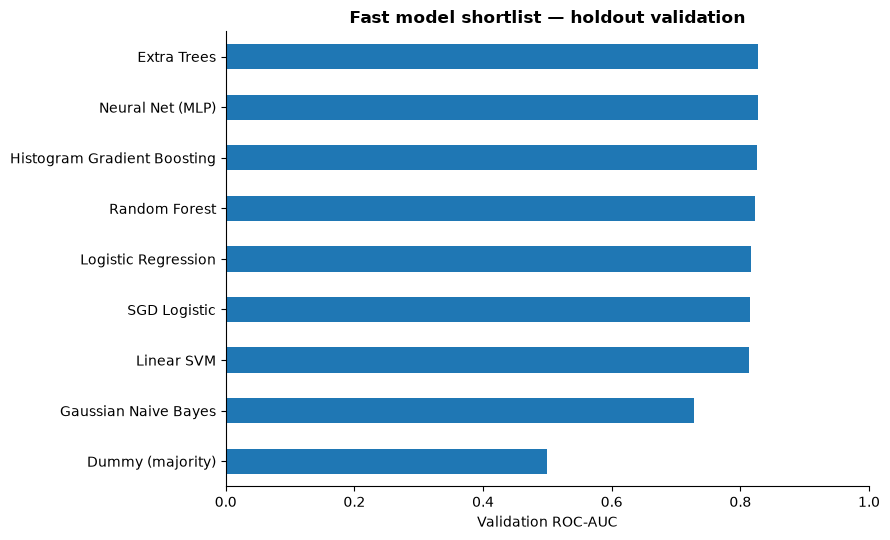

Top three by validation ROC-AUC:


,Model,ROC-AUC,PR-AUC,Precision,Recall,F1,Brier
6,Extra Trees,0.827,0.637,0.715,0.244,0.364,0.151
8,Neural Net (MLP),0.827,0.630,0.615,0.467,0.531,0.150
7,Histogram Gradient Boosting,0.827,0.634,0.645,0.423,0.511,0.150


Do not score the test split until the final tuned approach has been selected.


In [56]:
successful = scores[scores['Status'].eq('OK')].copy()
assert len(successful) >= 2, 'Too few models trained successfully; inspect error messages.'
ax = successful.sort_values('ROC-AUC').plot.barh(
    x='Model', y='ROC-AUC', legend=False, figsize=(9,5.5))
ax.set(xlabel='Validation ROC-AUC', ylabel='', title='Fast model shortlist — holdout validation')
ax.set_xlim(0,1)
plt.tight_layout()
plt.show()

shortlist = successful.head(3)[['Model','ROC-AUC','PR-AUC','Precision','Recall','F1','Brier']]
print('Top three by validation ROC-AUC:')
display(shortlist.round(3))
print('Do not score the test split until the final tuned approach has been selected.')

## 12.4 Interpretation and next steps

**What this experiment establishes:** which broad classifier families look promising under a consistent, intentionally cheap comparison. Some complex models may be disadvantaged by the smaller training set. The ranking is *provisional*.

**Next steps:** tune 2–3 shortlisted candidates with time-ordered CV, ensuring the **entire** feature engineering/preprocessing chain is re-fit per fold; then compare precision at high thresholds, PR-AUC, and probability calibration. Check robustness with `DROP_DEPOSIT_TYPE=True`, and assess the timing assumptions of historical fields. Only after those choices are locked should the final held-out test period be examined.

**Caution:** a booking-level classifier does not directly forecast how many rooms will be vacant on a given night. Linking this to Task 1 requires aggregation and a booking snapshot as of the forecast date.

In [57]:
# Optional lightweight export for GitHub / reports; disabled by default.
EXPORT_RESULTS = False
if EXPORT_RESULTS:
    output_dir = Path('../reports') if Path('../reports').exists() else Path('reports')
    output_dir.mkdir(exist_ok=True, parents=True)
    scores.to_csv(output_dir / 'model_shortlist_validation.csv', index=False)
    print('Wrote', output_dir / 'model_shortlist_validation.csv')